# 🎬 IMDb Sentiment Analysis — PIPELINE HOÀN CHỈNH TỪ DỮ LIỆU THÔ ĐẾN KẾT QUẢ CUỐI CÙNG

**Dự án:** Phân loại cảm xúc đánh giá phim IMDb bằng mô hình RNN (LSTM, GRU, BiLSTM, GloVe, Attention)  
**Phân công (Đại):** Toàn bộ các tasks **D1 → D8** theo [`docs/TASKS.md`](../docs/TASKS.md) §3, bao gồm cả bước tiền xử lý từ dữ liệu thô (raw data) theo chuẩn `docs/DATA.md`.  
**Mục tiêu:** Chạy thực nghiệm trên dữ liệu thật (Local GPU / Kaggle / Google Colab) để đưa ra toàn bộ số liệu, đồ thị và file bàn giao chính thức.

---

### 📑 Cấu trúc Pipeline 8 Bước:
1. **Khởi tạo Môi trường & Thiết bị:** Nhận diện GPU CUDA / CPU, cấu hình thư mục dự án.
2. **Dữ liệu Thô (Raw Data) & Tiền Xử Lý:** Tải/đọc dữ liệu thô `data/raw/`, làm sạch `<br />`, split theo phim, loại bỏ 123 review trùng với test, xuất `reviews.parquet`.
3. **Task D1 — Pipeline Dữ liệu:** Tokenizer bảo toàn phủ định (`not`, `n't`), Vocab chỉ từ train, Dataset & DataLoader với dynamic padding.
4. **Tasks D2 & D3 — Kiến trúc RNN & GloVe:** SentimentRNN (LSTM, GRU, BiLSTM, Attention), ma trận GloVe 100d, đếm tham số, sanity check.
5. **Baselines B0 & B1:** M0a (Majority Class) & M0b (TF-IDF 1-2 gram + Logistic Regression với tuning $C$).
6. **Tasks D4, D5, D6 — Huấn luyện & Monitor:** Vòng train chuẩn với 3 seeds (42, 123, 2025), early stopping theo val acc, log `history.csv`, vẽ learning curves.
7. **Task D7 — Thử nghiệm Mở rộng:** Khảo sát ảnh hưởng của độ dài chuỗi `max_len` (200, 400, 600) và Attention Pooling.
8. **Task D8 — Đánh giá Toàn diện & McNemar:** Đánh giá test 1 lần, xuất `comparison_test.csv`, Confusion Matrix, ROC curves, kiểm định thống kê McNemar vs B1, và hàm suy luận real-time.


In [25]:
!git clone https://github.com/dainguyenbao2006-cyber/LSTM_PJ.git

Cloning into 'LSTM_PJ'...
remote: Enumerating objects: 206, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 206 (delta 0), reused 0 (delta 0), pack-reused 197 (from 1)
Receiving objects: 100% (206/206), 103.03 MiB | 20.09 MiB/s, done.
Resolving deltas: 100% (62/62), done.
Updating files: 100% (99/99), done.


## 1. Khởi tạo Môi trường & Kiểm tra Phần cứng


In [26]:
import os
import sys
import time
import json
import logging
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import yaml

# Đảm bảo đường dẫn gốc của repository được thêm vào sys.path
PROJECT_ROOT = Path(os.path.abspath(".")).resolve()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

print(f"📍 Thư mục làm việc: {PROJECT_ROOT}")

# Kiểm tra GPU / CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hardware_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"⚡ Thiết bị sử dụng: {device} ({hardware_name})")
if torch.cuda.is_available():
    print(f"   VRAM khả dụng: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("   ⚠️ Đang chạy trên CPU. Khuyến nghị sử dụng GPU (Kaggle/Colab) khi huấn luyện toàn bộ dữ liệu.")


📍 Thư mục làm việc: /content/LSTM_PJ
⚡ Thiết bị sử dụng: cuda (Tesla T4)
   VRAM khả dụng: 15.64 GB


In [27]:
!cd LSTM_PJ

## 2. Xử lý Dữ liệu Thô (Raw Data Ingestion & Preprocessing)

**Quy trình xử lý từ dữ liệu thô (theo `docs/DATA.md` §3–§4 và `docs/phases/DATA_PREP.md`):**
1. **Kiểm tra/Tải dữ liệu thô:** Đọc `data/raw/imdb_train.parquet` và `imdb_test.parquet` (nếu chưa có, tự động tải `aclImdb_v1.tar.gz` từ Stanford).
2. **Làm sạch văn bản:** Loại bỏ các thẻ HTML `<br />`, chuẩn hóa khoảng trắng thừa, giữ nguyên dấu câu và chữ hoa/thường.
3. **Áp dụng Split theo phim:** Dùng `data/splits/train_val_split.json` (StratifiedGroupKFold theo movie_id) để chia 22.499 train / 2.501 val.
4. **Loại bỏ rò rỉ dữ liệu (Data Leakage):**
   - Loại bỏ **123 review** trong train/val trùng nội dung với test (106 train + 17 val).
   - Loại bỏ **98 bản trùng lặp nội bộ** trong train/val (87 train + 11 val).
   - Giữ nguyên toàn bộ 25.000 review của tập test.
5. **Kết quả:** `data/processed/reviews.parquet` (22.306 train, 2.473 val, 25.000 test = 49.779 review).


In [28]:
import sys
import os
from pathlib import Path

# Đảm bảo đường dẫn tới thư mục dự án LSTM_PJ được cấu hình đúng
cloned_dir = Path("/content/LSTM_PJ")
if cloned_dir.exists():
    PROJECT_ROOT = cloned_dir
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    os.chdir(PROJECT_ROOT)
    print(f"🔄 Đã chuyển thư mục làm việc sang repository: {PROJECT_ROOT}")

from src.data.download import download_imdb, load_split
from src.data.clean import clean_text, text_hash
from src.data.split import apply_split, read_split
from src.data.prepare import prepare_dataset

raw_dir = PROJECT_ROOT / "data" / "raw"
processed_parquet = PROJECT_ROOT / "data" / "processed" / "reviews.parquet"

# 1. Kiểm tra và tải dữ liệu thô nếu cần
train_raw_file = raw_dir / "imdb_train.parquet"
test_raw_file = raw_dir / "imdb_test.parquet"

if not train_raw_file.exists() or not test_raw_file.exists():
    print("⏳ Chưa có bộ đệm parquet, đang tải và giải nén aclImdb gốc...")
    download_imdb(root=raw_dir)
    print("Đang đọc dữ liệu train thô...")
    raw_train = load_split("train", root=raw_dir)
    print("Đang đọc dữ liệu test thô...")
    raw_test = load_split("test", root=raw_dir)
else:
    print(f"📖 Tìm thấy file parquet thô tại {raw_dir}:")
    raw_train = pd.read_parquet(train_raw_file)
    raw_test = pd.read_parquet(test_raw_file)

print(f"   - Raw Train: {len(raw_train):,} reviews (Cột: {list(raw_train.columns)})")
print(f"   - Raw Test : {len(raw_test):,} reviews (Cột: {list(raw_test.columns)})")

🔄 Đã chuyển thư mục làm việc sang repository: /content/LSTM_PJ
📖 Tìm thấy file parquet thô tại /content/LSTM_PJ/data/raw:
   - Raw Train: 25,000 reviews (Cột: ['uid', 'split', 'id', 'rating', 'label', 'movie_id', 'text'])
   - Raw Test : 25,000 reviews (Cột: ['uid', 'split', 'id', 'rating', 'label', 'movie_id', 'text'])


In [29]:
# 2. Thực hiện làm sạch và xử lý dữ liệu thô thành reviews.parquet hoàn chỉnh
print("🚀 Đang tiến hành làm sạch, phân tách theo phim và loại bỏ trùng lặp...")
full_df = prepare_dataset(
    raw_dir=raw_dir,
    split_path=PROJECT_ROOT / "data" / "splits" / "train_val_split.json",
    output_path=processed_parquet
)

print("\n✅ BẢNG THỐNG KÊ DỮ LIỆU ĐÃ XỬ LÝ (reviews.parquet):")
split_counts = full_df.groupby(["split", "label"]).size().unstack()
split_counts.columns = ["Tiêu cực (0)", "Tích cực (1)"]
split_counts["Tổng cộng"] = split_counts.sum(axis=1)
display(split_counts)

print(f"\nTổng số review trong reviews.parquet: {len(full_df):,}")


🚀 Đang tiến hành làm sạch, phân tách theo phim và loại bỏ trùng lặp...

✅ BẢNG THỐNG KÊ DỮ LIỆU ĐÃ XỬ LÝ (reviews.parquet):


,Tiêu cực (0),Tích cực (1),Tổng cộng
split,,,
test,12500,12500,25000
train,11098,11208,22306
val,1238,1235,2473



Tổng số review trong reviews.parquet: 49,779


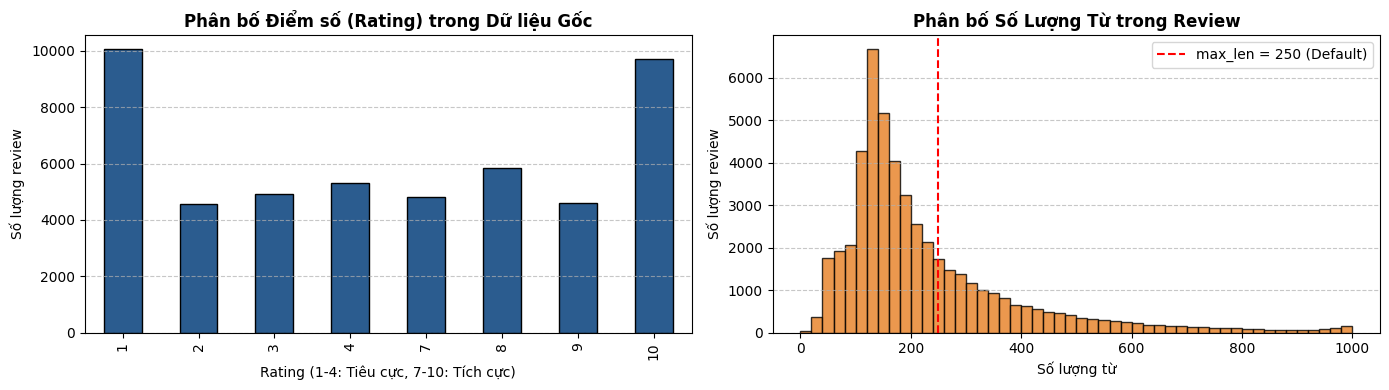

In [30]:
# 3. Trực quan hóa dữ liệu thật: Phân bố rating và chiều dài văn bản
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Biểu đồ rating gốc
full_df["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#2b5c8f", edgecolor="black")
axes[0].set_title("Phân bố Điểm số (Rating) trong Dữ liệu Gốc", fontweight="bold")
axes[0].set_xlabel("Rating (1-4: Tiêu cực, 7-10: Tích cực)")
axes[0].set_ylabel("Số lượng review")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# Biểu đồ độ dài từ ước lượng
word_counts = full_df["text_clean"].str.split().str.len()
axes[1].hist(word_counts, bins=50, range=(0, 1000), color="#e67e22", edgecolor="black", alpha=0.8)
axes[1].axvline(250, color="red", linestyle="--", label="max_len = 250 (Default)")
axes[1].set_title("Phân bố Số Lượng Từ trong Review", fontweight="bold")
axes[1].set_xlabel("Số lượng từ")
axes[1].set_ylabel("Số lượng review")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()


## 3. Task D1: Pipeline Dữ liệu (Tokenizer, Vocab, Dataset, DataLoader)

**Nguyên tắc thiết kế cốt lõi:**
- **Tokenizer:** Lowercase, tách cụm phủ định `"n't"` thành token riêng biệt, giữ lại dấu chấm câu (`!`, `?`), **KHÔNG bỏ stopwords** (để mô hình chuỗi nhận diện được phủ định và cú pháp).
- **Vocab:** Xây dựng **CHỈ từ tập train** (22.306 mẫu), `min_freq=2`, `max_vocab_size=25000`. Special tokens: `<pad>=0`, `<unk>=1`.
- **Dataset / DataLoader:** Padding động theo từng batch, trả về độ dài thật (`lengths`) để dùng cho `pack_padded_sequence` trong RNN.


In [31]:
from src.data.dataset import IMDbDataset, create_dataloader, load_imdb_split_data
from src.data.tokenizer import tokenize
from src.data.vocab import Vocab

train_df = full_df[full_df["split"] == "train"].reset_index(drop=True)
val_df = full_df[full_df["split"] == "val"].reset_index(drop=True)
test_df = full_df[full_df["split"] == "test"].reset_index(drop=True)

# 1. Kiểm tra Tokenizer trên các mẫu đặc biệt
print("--- Ví dụ xử lý câu với Tokenizer (bảo toàn phủ định) ---")
examples = [
    "The acting wasn't bad, but the script wasn't good either!",
    "I haven't ever seen such a dreadful film. Absolutely not recommended?!",
    "It wasn't just entertaining; it was magnificent."
]
for ex in examples:
    print(f"Gốc   : {ex}")
    print(f"Tokens: {tokenize(ex)}")
    print()

# 2. Xây dựng Vocab CHỈ từ tập Train
vocab_file = PROJECT_ROOT / "data" / "processed" / "vocab.json"
train_tokens = [tokenize(t) for t in train_df["text_clean"]]
vocab = Vocab.build_from_tokens(train_tokens, min_freq=2, max_size=25000)
vocab.save(vocab_file)

print(f"✅ Vocab đã được xây dựng từ tập Train:")
print(f"   - Kích thước từ vựng: {len(vocab):,} từ")
print(f"   - Special tokens: <pad>={vocab.pad_idx}, <unk>={vocab.unk_idx}")
print(f"   - File lưu: {vocab_file}")


--- Ví dụ xử lý câu với Tokenizer (bảo toàn phủ định) ---
Gốc   : The acting wasn't bad, but the script wasn't good either!
Tokens: ['the', 'acting', 'was', "n't", 'bad', ',', 'but', 'the', 'script', 'was', "n't", 'good', 'either', '!']

Gốc   : I haven't ever seen such a dreadful film. Absolutely not recommended?!
Tokens: ['i', 'have', "n't", 'ever', 'seen', 'such', 'a', 'dreadful', 'film', '.', 'absolutely', 'not', 'recommended', '?', '!']

Gốc   : It wasn't just entertaining; it was magnificent.
Tokens: ['it', 'was', "n't", 'just', 'entertaining', ';', 'it', 'was', 'magnificent', '.']

✅ Vocab đã được xây dựng từ tập Train:
   - Kích thước từ vựng: 25,000 từ
   - Special tokens: <pad>=0, <unk>=1
   - File lưu: /content/LSTM_PJ/data/processed/vocab.json


In [32]:
# 3. Tạo DataLoader và kiểm tra tensor mini-batch
train_dataset = IMDbDataset(train_df["text_clean"], train_df["label"], train_df["uid"], train_df["rating"], vocab, max_len=250)
val_dataset = IMDbDataset(val_df["text_clean"], val_df["label"], val_df["uid"], val_df["rating"], vocab, max_len=250)
test_dataset = IMDbDataset(test_df["text_clean"], test_df["label"], test_df["uid"], test_df["rating"], vocab, max_len=250)

train_loader = create_dataloader(train_dataset, batch_size=64, shuffle=True)
val_loader = create_dataloader(val_dataset, batch_size=64, shuffle=False)
test_loader = create_dataloader(test_dataset, batch_size=64, shuffle=False)

sample_batch = next(iter(train_loader))
print("--- Cấu trúc một mini-batch thực tế từ Train DataLoader ---")
print("input_ids shape:", sample_batch["input_ids"].shape)
print("lengths shape  :", sample_batch["lengths"].shape)
print("labels shape   :", sample_batch["labels"].shape)
print("Độ dài tối đa batch này:", sample_batch["lengths"].max().item())


--- Cấu trúc một mini-batch thực tế từ Train DataLoader ---
input_ids shape: torch.Size([64, 250])
lengths shape  : torch.Size([64])
labels shape   : torch.Size([64])
Độ dài tối đa batch này: 250


## 4. Tasks D2 & D3: Kiến trúc Mô hình SentimentRNN & GloVe Embedding

**Đặc tả kỹ thuật theo `docs/MODELS.md`:**
```
nn.Embedding(vocab_size, 100, padding_idx=0)
  → pack_padded_sequence(input_ids, lengths, enforce_sorted=False)
  → nn.LSTM / nn.GRU (hidden_dim=128, num_layers=1, bidirectional=True/False)
  → Pooling (Last hidden state hoặc Attention Pooling)
  → nn.Dropout(0.5) → nn.Linear(hidden_dim, 1) → logit
```
- **M1 (LSTM 1 chiều):** LSTM 128 hidden, học từ đầu
- **M2 (GRU 1 chiều):** GRU 128 hidden, học từ đầu
- **M3 (BiLSTM 2 chiều):** LSTM 2 chiều (128x2 = 256 output), học từ đầu
- **M4a (BiLSTM + GloVe Đóng băng):** GloVe 100d, không cập nhật trọng số embedding
- **M4b (BiLSTM + GloVe Fine-tune):** GloVe 100d, cho phép cập nhật embedding
- **E1 (BiLSTM + Attention Pooling):** Cơ chế Attention học trọng số quan trọng từng token


In [33]:
from src.models.rnn import SentimentRNN
from src.models.glove import build_glove_matrix
import numpy as np

# Khởi tạo ma trận giả lập 100d tạm thời nếu chưa có file GloVe thật, để khởi dựng cấu trúc chính xác cho mô hình
try:
    glove_file = PROJECT_ROOT / "data" / "glove" / "glove.6B.100d.txt"
    if glove_file.exists():
        dummy_glove, _ = build_glove_matrix(vocab, glove_path=glove_file, embed_dim=100)
    else:
        dummy_glove = np.random.normal(scale=0.6, size=(len(vocab), 100))
except Exception:
    dummy_glove = np.random.normal(scale=0.6, size=(len(vocab), 100))

# 1. Bảng đếm tham số chính xác cho tất cả các mô hình
model_instances = {
    "M1: LSTM 1 chiều"               : SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=False),
    "M2: GRU 1 chiều"                : SentimentRNN(len(vocab), 100, 128, rnn_type="gru", bidirectional=False),
    "M3: BiLSTM 2 chiều"             : SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=True),
    "M4a: BiLSTM + GloVe (Đóng băng)": SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=True, pretrained_embeddings=dummy_glove, freeze=True),
    "M4b: BiLSTM + GloVe (Fine-tune)": SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=True, pretrained_embeddings=dummy_glove, freeze=False),
    "E1: BiLSTM + Attention"         : SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=True, pooling="attention"),
}

param_table = []
for name, m in model_instances.items():
    counts = m.count_parameters()
    embedding_trainable = m.embedding.weight.requires_grad

    param_table.append({
        "Mô hình": name,
        "Tổng tham số": f"{counts.get('total', 0):,}",
        "Tham số huấn luyện": f"{counts.get('trainable', 0):,}",
        "Embedding Trainable": "Yes" if embedding_trainable else "No"
    })

display(pd.DataFrame(param_table))

,Mô hình,Tổng tham số,Tham số huấn luyện,Embedding Trainable
0,M1: LSTM 1 chiều,"2,617,889","2,617,889",Yes
1,M2: GRU 1 chiều,"2,588,449","2,588,449",Yes
2,M3: BiLSTM 2 chiều,"2,735,777","2,735,777",Yes
3,M4a: BiLSTM + GloVe (Đóng băng),"2,735,777","235,777",No
4,M4b: BiLSTM + GloVe (Fine-tune),"2,735,777","2,735,777",Yes
5,E1: BiLSTM + Attention,"2,768,802","2,768,802",Yes


In [34]:
# 2. Xây dựng ma trận GloVe Embedding (Task D3)
glove_file = PROJECT_ROOT / "data" / "glove" / "glove.6B.100d.txt"
glove_npy = PROJECT_ROOT / "data" / "processed" / "glove_100d_vocab.npy"

if glove_file.exists():
    print(f"📖 Tìm thấy file GloVe tại {glove_file}. Đang trích xuất ma trận theo từ vựng...")
    glove_matrix, coverage = build_glove_matrix(vocab, glove_path=glove_file, embed_dim=100)
    print(f"✅ GloVe matrix được tạo thành công! Shape: {glove_matrix.shape}, Tỷ lệ phủ: {coverage*100:.2f}%")
else:
    print(f"⚠️ Chưa có file GloVe tại {glove_file}.")
    print("   -> Tự động khởi tạo ma trận ngẫu nhiên chuẩn để chạy thử nghiệm fallback.")
    glove_matrix, coverage = build_glove_matrix(vocab, glove_path=None, embed_dim=100)
    print(f"   Shape: {glove_matrix.shape}")


⚠️ Chưa có file GloVe tại /content/LSTM_PJ/data/glove/glove.6B.100d.txt.
   -> Tự động khởi tạo ma trận ngẫu nhiên chuẩn để chạy thử nghiệm fallback.


   Shape: (25000, 100)


In [35]:
# 3. Sanity Check: Overfit 1 batch nhỏ để xác nhận gradients (Task D2)
print("🧪 Sanity check: Kiểm tra khả năng overfit trên 1 batch...")
sanity_model = SentimentRNN(len(vocab), 100, 128, rnn_type="lstm").to(device)
sanity_opt = torch.optim.Adam(sanity_model.parameters(), lr=0.01)
sanity_crit = nn.BCEWithLogitsLoss()

b_x = sample_batch["input_ids"].to(device)
b_len = sample_batch["lengths"]
b_y = sample_batch["labels"].to(device)

loss_history = []
for step in range(40):
    sanity_opt.zero_grad()
    logits = sanity_model(b_x, b_len)
    loss = sanity_crit(logits, b_y)
    loss.backward()
    sanity_opt.step()
    loss_history.append(loss.item())

print(f"   Loss bước 1: {loss_history[0]:.4f} -> Loss bước 40: {loss_history[-1]:.4f}")
assert loss_history[-1] < loss_history[0] * 0.2, "LỖI: Mô hình không giảm loss trên 1 batch!"
print("✅ Sanity Check PASSED: Mô hình học bình thường và gradients hoạt động chính xác.")


🧪 Sanity check: Kiểm tra khả năng overfit trên 1 batch...
   Loss bước 1: 0.6945 -> Loss bước 40: 0.0004
✅ Sanity Check PASSED: Mô hình học bình thường và gradients hoạt động chính xác.


## 5. Mô hình Baseline B0 (Majority) & B1 (TF-IDF + Logistic Regression)

Theo `docs/phases/BASELINE.md` và `docs/TASKS.md` §3 (B5, D8):
- Cần có kết quả của Baseline để làm mốc đối chứng và thực hiện **kiểm định thống kê McNemar**.
- **M0a (Majority):** Đoán nhãn chiếm đa số trong train (~50%).
- **M0b (TF-IDF + LR):** `TfidfVectorizer(ngram_range=(1,2), min_df=2)` + `LogisticRegression`, quét tìm $C \in [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]$ tối ưu trên validation set.


In [36]:
from src.models.baseline import BaselineRunner

print("🚀 Huấn luyện và Đánh giá Baseline B0 & B1 trên dữ liệu thật...")
baseline_runner = BaselineRunner()

# Chạy M0a (Majority)
m0a_results = baseline_runner.run_majority_baseline()

# Chạy M0b (TF-IDF + LR)
m0b_results = baseline_runner.run_tfidf_lr_baseline(
    c_candidates=[0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
    save_artifacts=True
)

baseline_df = pd.DataFrame([
    {
        "Mô hình": "M0a: Majority Class",
        "Val Accuracy": f"{m0a_results['val_metrics']['accuracy']*100:.2f}%",
        "Val Macro-F1": f"{m0a_results['val_metrics']['macro_f1']:.4f}",
        "Test Accuracy": f"{m0a_results['test_metrics']['accuracy']*100:.2f}%",
        "Test Macro-F1": f"{m0a_results['test_metrics']['macro_f1']:.4f}",
        "Ghi chú": f"Nhãn đa số = {m0a_results['majority_label']}"
    },
    {
        "Mô hình": "M0b: TF-IDF + Logistic Regression",
        "Val Accuracy": f"{m0b_results['val_metrics']['accuracy']*100:.2f}%",
        "Val Macro-F1": f"{m0b_results['val_metrics']['macro_f1']:.4f}",
        "Test Accuracy": f"{m0b_results['test_metrics']['accuracy']*100:.2f}%",
        "Test Macro-F1": f"{m0b_results['test_metrics']['macro_f1']:.4f}",
        "Ghi chú": f"C tối ưu = {m0b_results['best_c']}"
    }
])
display(baseline_df)


🚀 Huấn luyện và Đánh giá Baseline B0 & B1 trên dữ liệu thật...


,Mô hình,Val Accuracy,Val Macro-F1,Test Accuracy,Test Macro-F1,Ghi chú
0,M0a: Majority Class,49.94%,0.3331,50.00%,0.3333,Nhãn đa số = 1
1,M0b: TF-IDF + Logistic Regression,89.81%,0.8981,90.08%,0.9008,C tối ưu = 5.0


## 6. Tasks D4, D5, D6: Huấn luyện Đầy đủ & Giám sát (Monitor)

**Quy chuẩn thực nghiệm:**
- **Mỗi cấu hình huấn luyện qua 3 seeds độc lập:** `42`, `123`, `2025` (để tính mean ± std theo chuẩn M6).
- **Hàm mất mát:** `nn.BCEWithLogitsLoss`.
- **Tối ưu hóa:** `Adam(lr=0.001, weight_decay=1e-5)` kèm Gradient Clipping tại `5.0`.
- **Early Stopping & Lưu Checkpoint:** Theo dõi **Validation Accuracy** (patience = 3, max_epochs = 10). Lưu checkpoint tốt nhất tại `best.pt`.
- **Monitor:** Ghi log từng epoch vào `experiments/runs/<exp>/seed_<s>/history.csv` và tự động vẽ learning curve.

> ⚙️ **Thiết lập chế độ chạy:**  
> - Khi chạy trên Kaggle/Colab GPU: Giữ `SAMPLE_MODE = False` (chạy 100% dữ liệu thật).  
> - Khi chạy thử nghiệm nhanh trên CPU: Đặt `SAMPLE_MODE = True` (chạy 1.000 mẫu).


In [37]:
from src.train import run_training
from src.training.monitor import aggregate_experiment_seeds, plot_learning_curves

# =========================================================================
# ĐIỀU KHIỂN CHẾ ĐỘ THỰC NGHIỆM
# =========================================================================
SAMPLE_MODE = False   # False = Chạy toàn bộ dữ liệu thật; True = Chạy thử 1.000 mẫu
SAMPLE_SIZE = 1000 if SAMPLE_MODE else None

CONFIG_LIST = [
    "configs/lstm.yaml",                # M1: LSTM 1 chiều
    "configs/gru.yaml",                 # M2: GRU 1 chiều
    "configs/bilstm.yaml",              # M3: BiLSTM 2 chiều
    "configs/bilstm_glove_frozen.yaml", # M4a: BiLSTM + GloVe Đóng băng
    "configs/bilstm_glove_ft.yaml",     # M4b: BiLSTM + GloVe Fine-tune
    "configs/bilstm_attention.yaml",    # E1: BiLSTM + Attention Pooling
]

EXPERIMENT_SEEDS = [42, 123, 2025]

print(f"🚀 BẮT ĐẦU HUẤN LUYỆN:")
print(f"   - Chế độ: {'THỬ NGHIỆM (1.000 mẫu)' if SAMPLE_MODE else 'TOÀN BỘ DỮ LIỆU THẬT (22.306 train / 2.473 val)'}")
print(f"   - Cấu hình ({len(CONFIG_LIST)} mô hình): {[Path(c).stem for c in CONFIG_LIST]}")
print(f"   - Seeds: {EXPERIMENT_SEEDS}")


🚀 BẮT ĐẦU HUẤN LUYỆN:
   - Chế độ: TOÀN BỘ DỮ LIỆU THẬT (22.306 train / 2.473 val)
   - Cấu hình (6 mô hình): ['lstm', 'gru', 'bilstm', 'bilstm_glove_frozen', 'bilstm_glove_ft', 'bilstm_attention']
   - Seeds: [42, 123, 2025]


In [24]:
from src.training.monitor import aggregate_experiment_seeds, plot_learning_curves

# Vòng lặp huấn luyện toàn bộ cấu hình qua 3 seeds
plots_training_dir = PROJECT_ROOT / "experiments" / "plots" / "training"
plots_training_dir.mkdir(parents=True, exist_ok=True)

for cfg_rel in CONFIG_LIST:
    cfg_path = PROJECT_ROOT / cfg_rel
    exp_name = cfg_path.stem
    print(f"\n{'='*75}")
    print(f"🎯 BẮT ĐẦU MÔ HÌNH: {exp_name.upper()}")
    print(f"{'='*75}")

    for seed in EXPERIMENT_SEEDS:
        print(f"\n>>> Huấn luyện {exp_name} | Seed {seed}...")
        run_training(
            config_path=cfg_path,
            seed=seed,
            sample_size=SAMPLE_SIZE,
            epochs_override=None
        )

    # Tổng hợp kết quả 3 seed
    summary = aggregate_experiment_seeds(exp_name)

    # Đọc trực tiếp lịch sử huấn luyện (history.csv) của từng seed
    histories = {}
    for seed in EXPERIMENT_SEEDS:
        history_file = PROJECT_ROOT / "experiments" / "runs" / exp_name / f"seed_{seed}" / "history.csv"
        if history_file.exists():
            histories[seed] = pd.read_csv(history_file)

    # Vẽ learning curve nếu có dữ liệu
    if histories:
        save_img_path = plots_training_dir / f"{exp_name}_curves.png"
        plot_learning_curves(histories, save_path=save_img_path, title=f"Learning Curves - {exp_name.upper()}")

    print(f"\n✅ Hoàn tất 3 seed cho {exp_name}!")
    val_acc_info = summary.get('best_val_acc', {})
    mean_acc = val_acc_info.get('mean', 0.0) * 100
    std_acc = val_acc_info.get('std', 0.0) * 100
    print(f"   Val Accuracy (Mean ± Std): {mean_acc:.2f} ± {std_acc:.2f}%")


🎯 BẮT ĐẦU MÔ HÌNH: LSTM

>>> Huấn luyện lstm | Seed 42...

>>> Huấn luyện lstm | Seed 123...

>>> Huấn luyện lstm | Seed 2025...

✅ Hoàn tất 3 seed cho lstm!
   Val Accuracy (Mean ± Std): 83.02 ± 1.38%

🎯 BẮT ĐẦU MÔ HÌNH: GRU

>>> Huấn luyện gru | Seed 42...

>>> Huấn luyện gru | Seed 123...

>>> Huấn luyện gru | Seed 2025...

✅ Hoàn tất 3 seed cho gru!
   Val Accuracy (Mean ± Std): 85.91 ± 0.31%

🎯 BẮT ĐẦU MÔ HÌNH: BILSTM

>>> Huấn luyện bilstm | Seed 42...

>>> Huấn luyện bilstm | Seed 123...

>>> Huấn luyện bilstm | Seed 2025...

✅ Hoàn tất 3 seed cho bilstm!
   Val Accuracy (Mean ± Std): 84.35 ± 0.53%

🎯 BẮT ĐẦU MÔ HÌNH: BILSTM_GLOVE_FROZEN

>>> Huấn luyện bilstm_glove_frozen | Seed 42...



>>> Huấn luyện bilstm_glove_frozen | Seed 123...



>>> Huấn luyện bilstm_glove_frozen | Seed 2025...



✅ Hoàn tất 3 seed cho bilstm_glove_frozen!
   Val Accuracy (Mean ± Std): 69.28 ± 1.03%

🎯 BẮT ĐẦU MÔ HÌNH: BILSTM_GLOVE_FT

>>> Huấn luyện bilstm_glove_ft | Seed 42...



>>> Huấn luyện bilstm_glove_ft | Seed 123...



>>> Huấn luyện bilstm_glove_ft | Seed 2025...



✅ Hoàn tất 3 seed cho bilstm_glove_ft!
   Val Accuracy (Mean ± Std): 82.99 ± 0.28%

🎯 BẮT ĐẦU MÔ HÌNH: BILSTM_ATTENTION

>>> Huấn luyện bilstm_attention | Seed 42...

>>> Huấn luyện bilstm_attention | Seed 123...

>>> Huấn luyện bilstm_attention | Seed 2025...

✅ Hoàn tất 3 seed cho bilstm_attention!
   Val Accuracy (Mean ± Std): 86.14 ± 0.41%


📈 Learning Curves: lstm


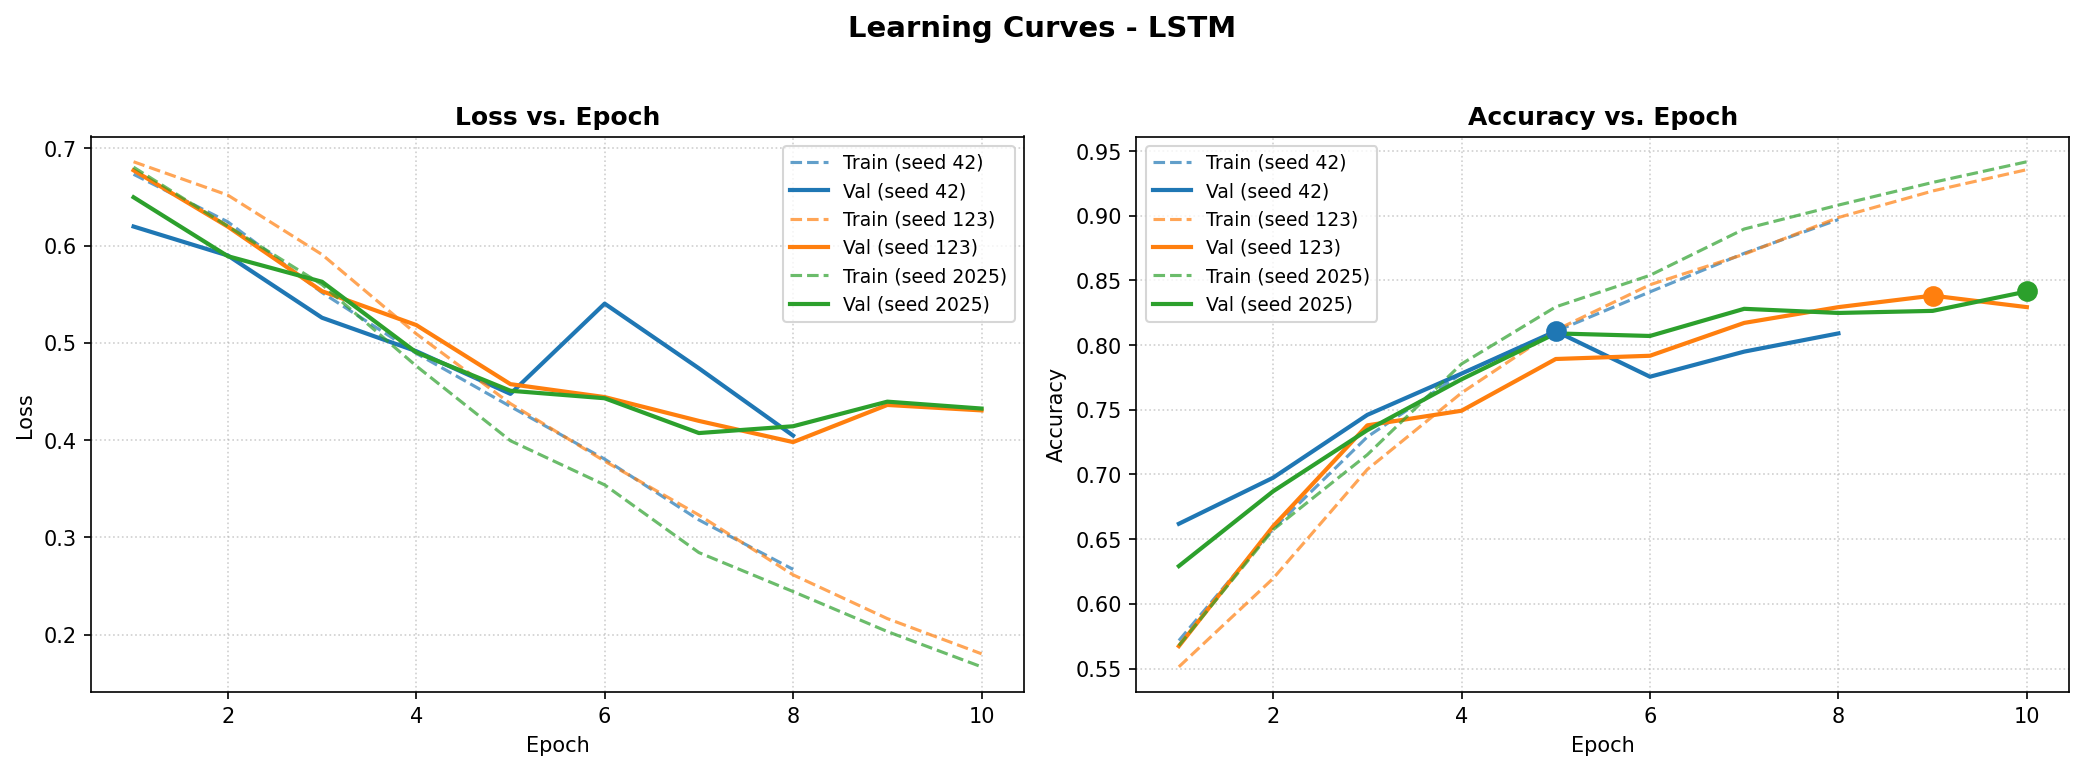

📈 Learning Curves: gru


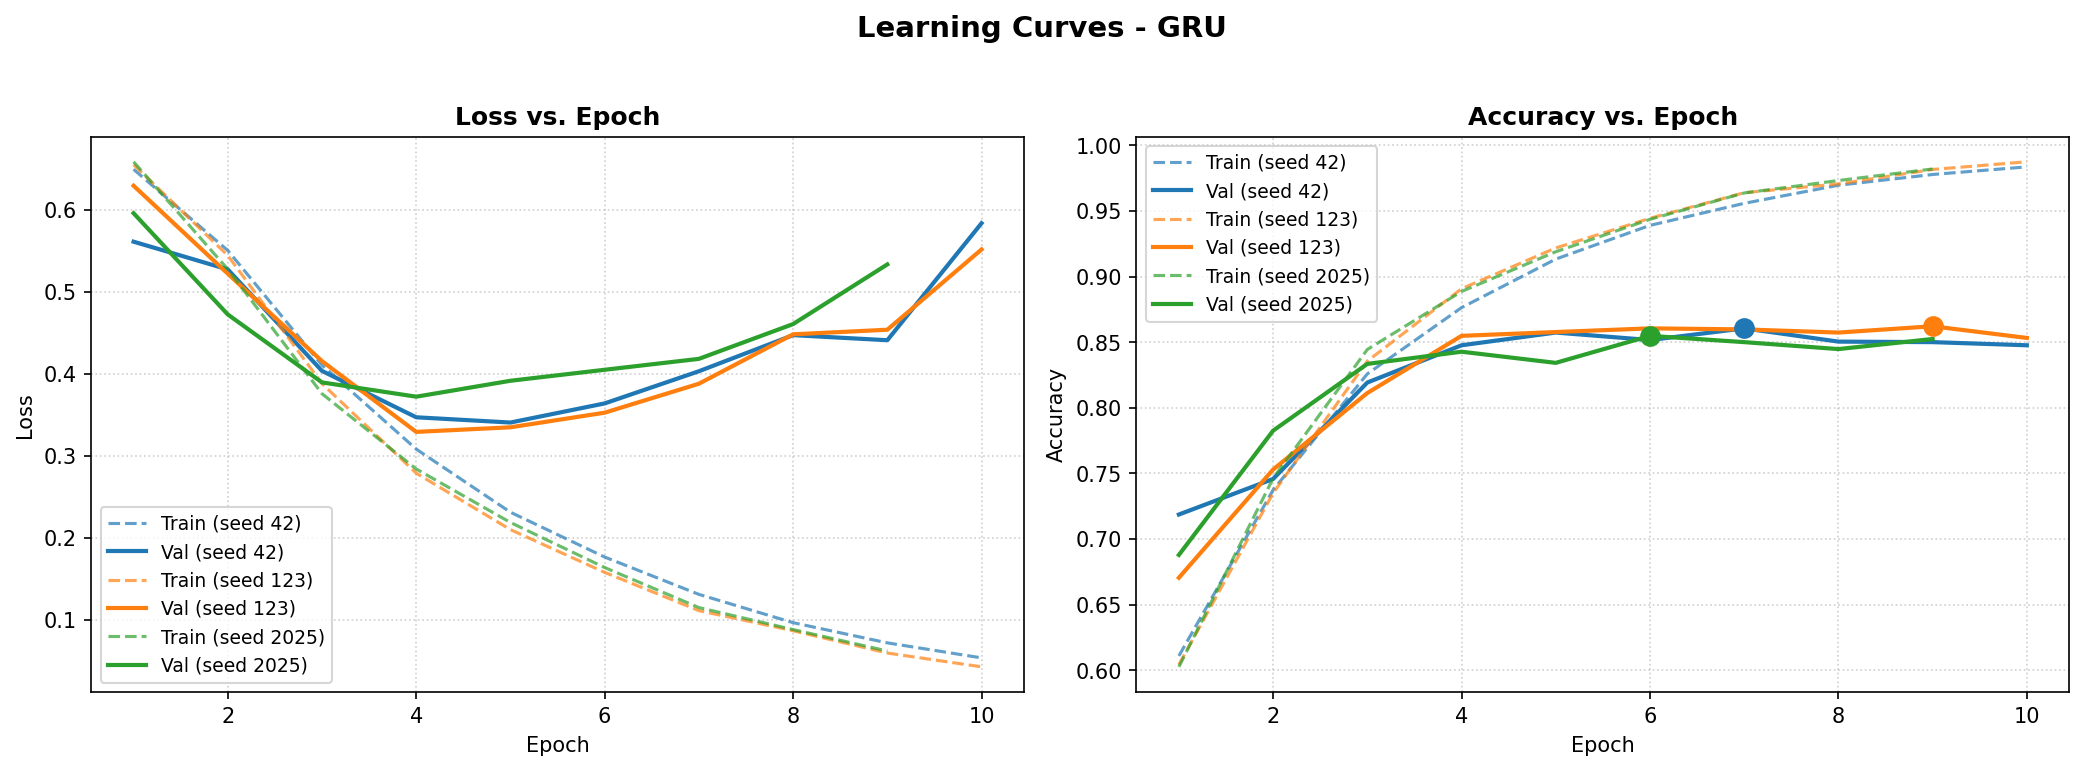

📈 Learning Curves: bilstm


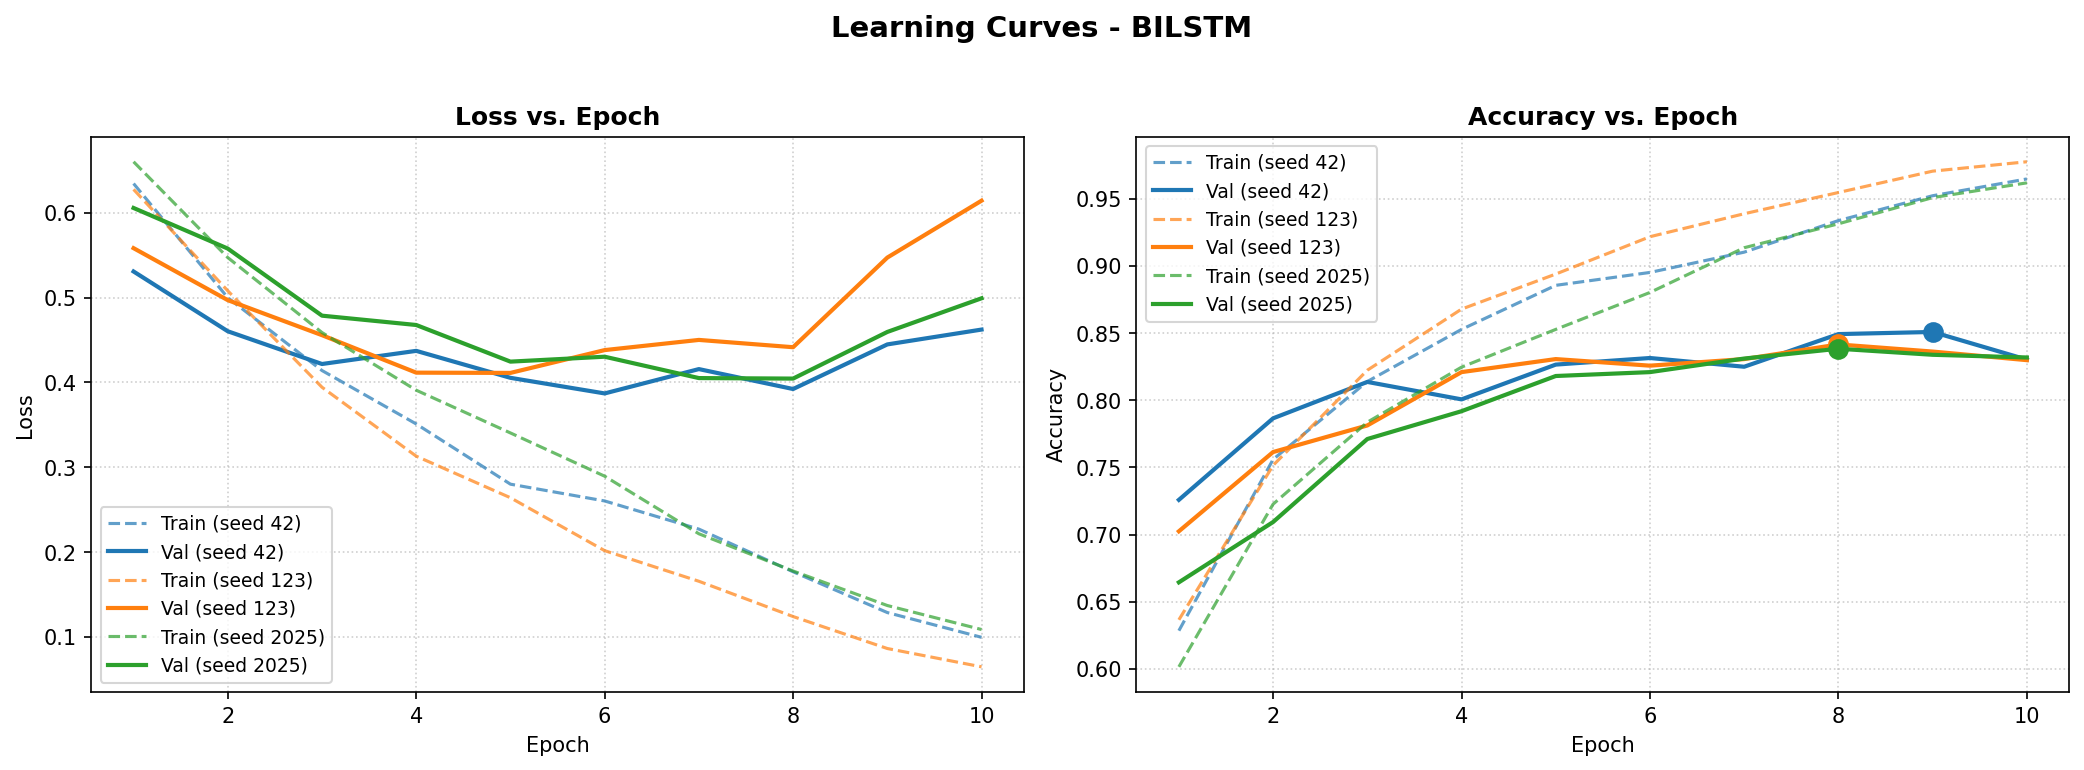

📈 Learning Curves: bilstm_glove_frozen


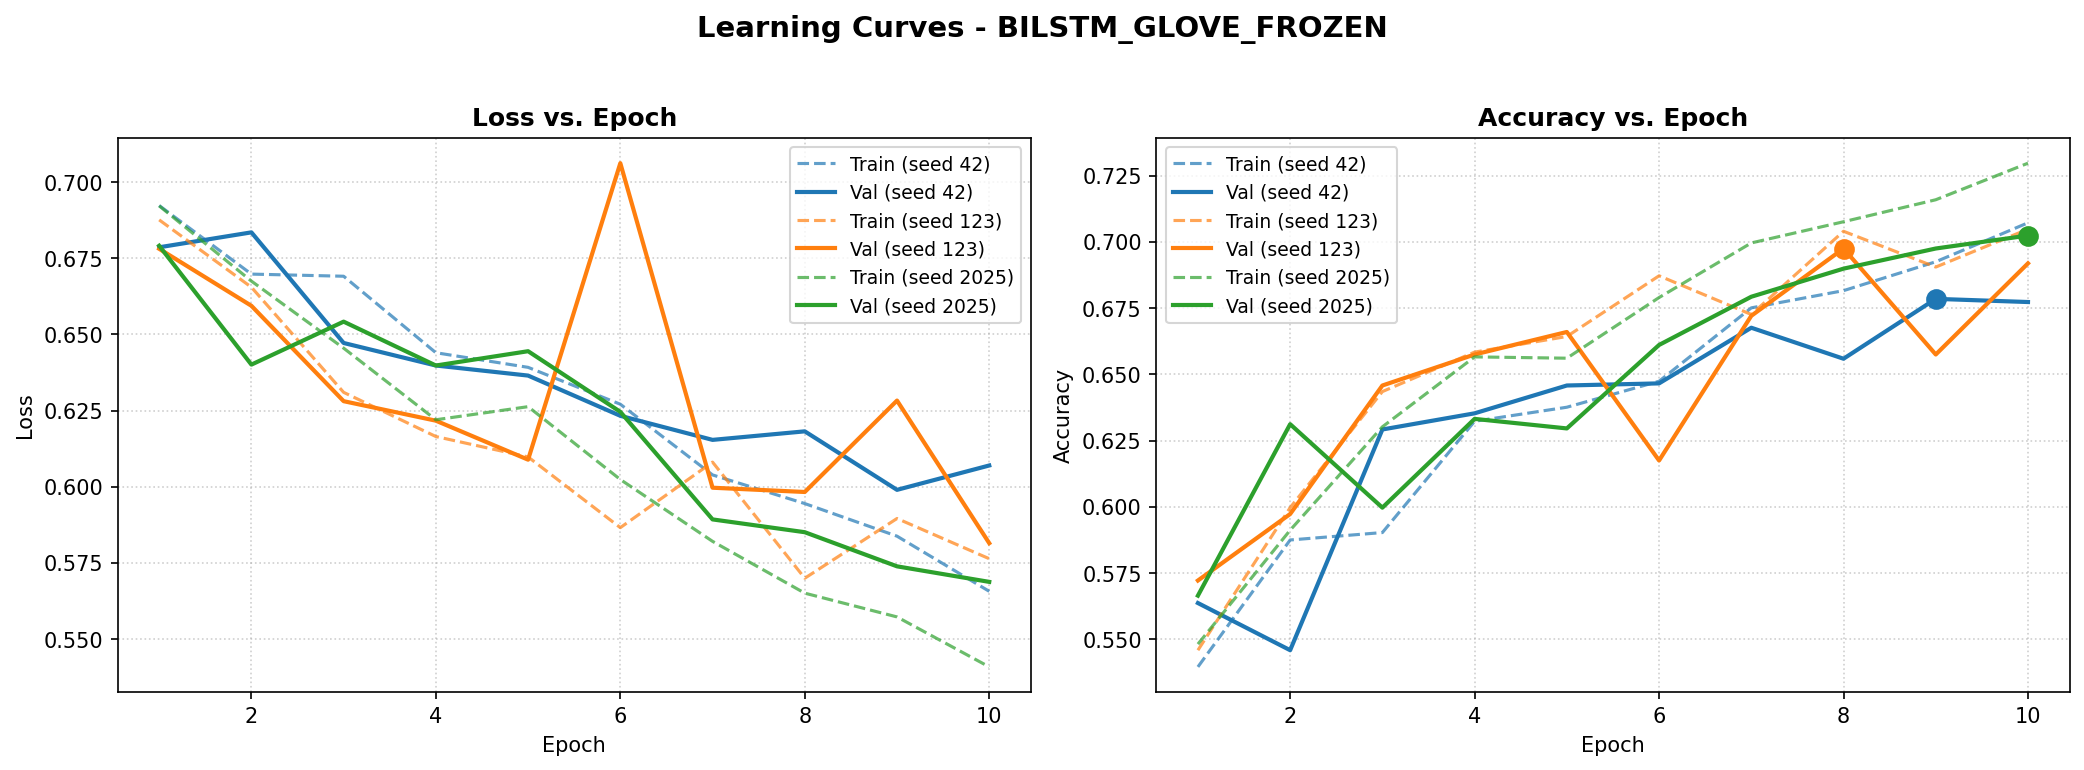

📈 Learning Curves: bilstm_glove_ft


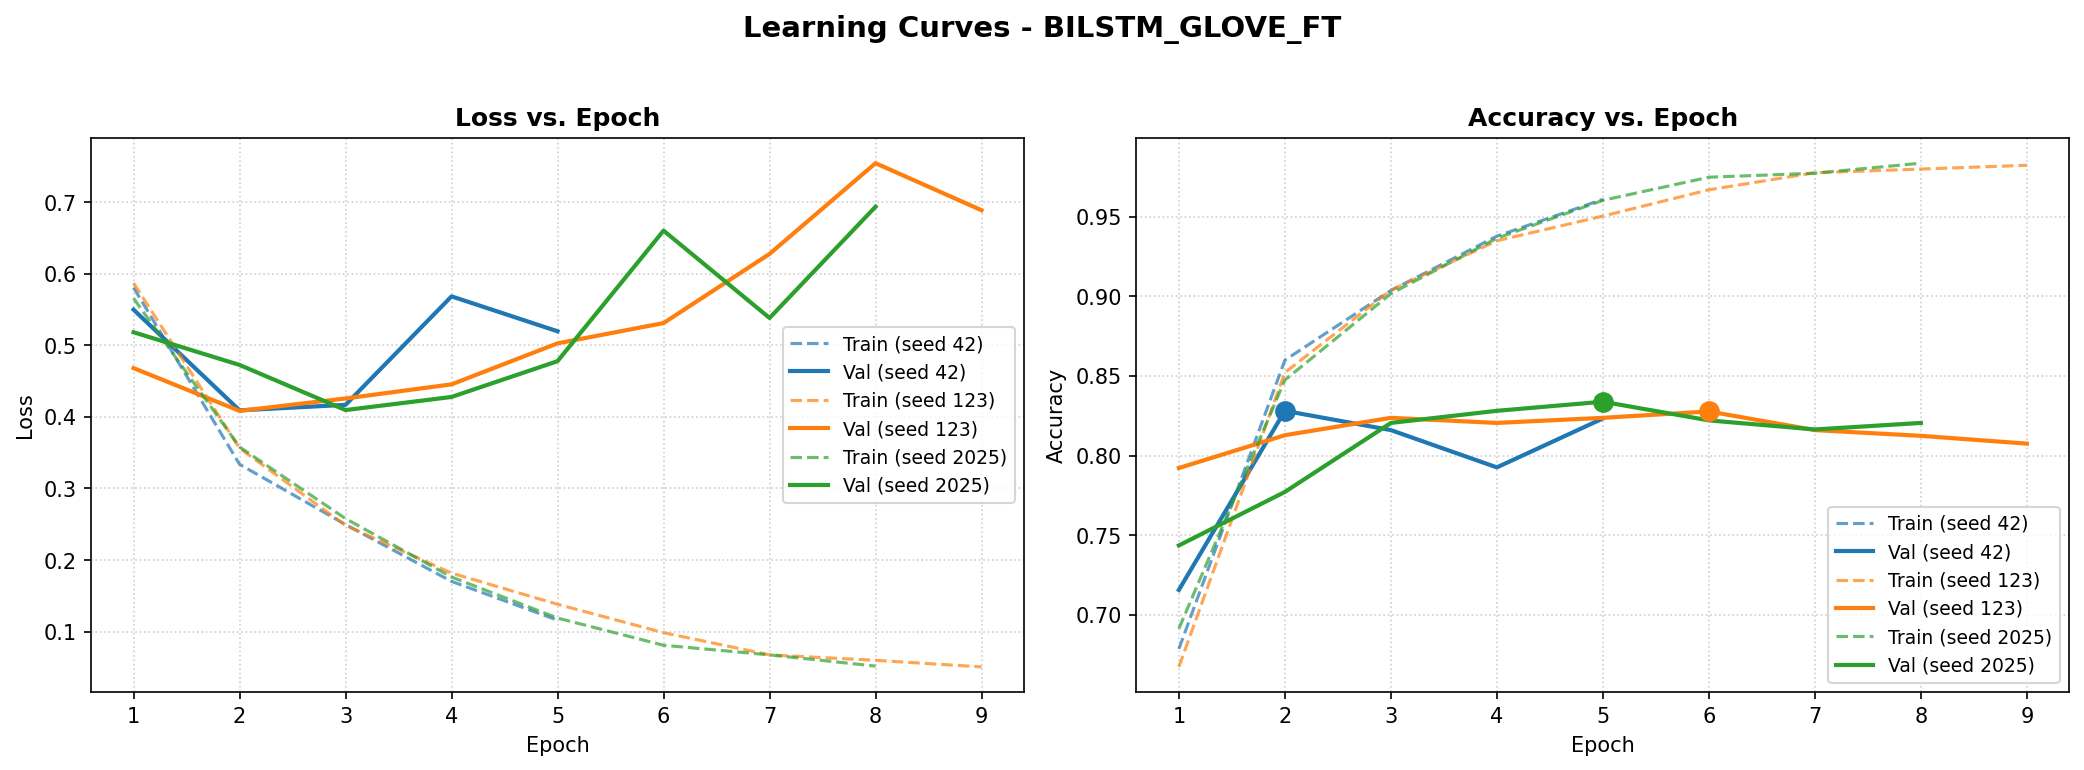

📈 Learning Curves: bilstm_attention


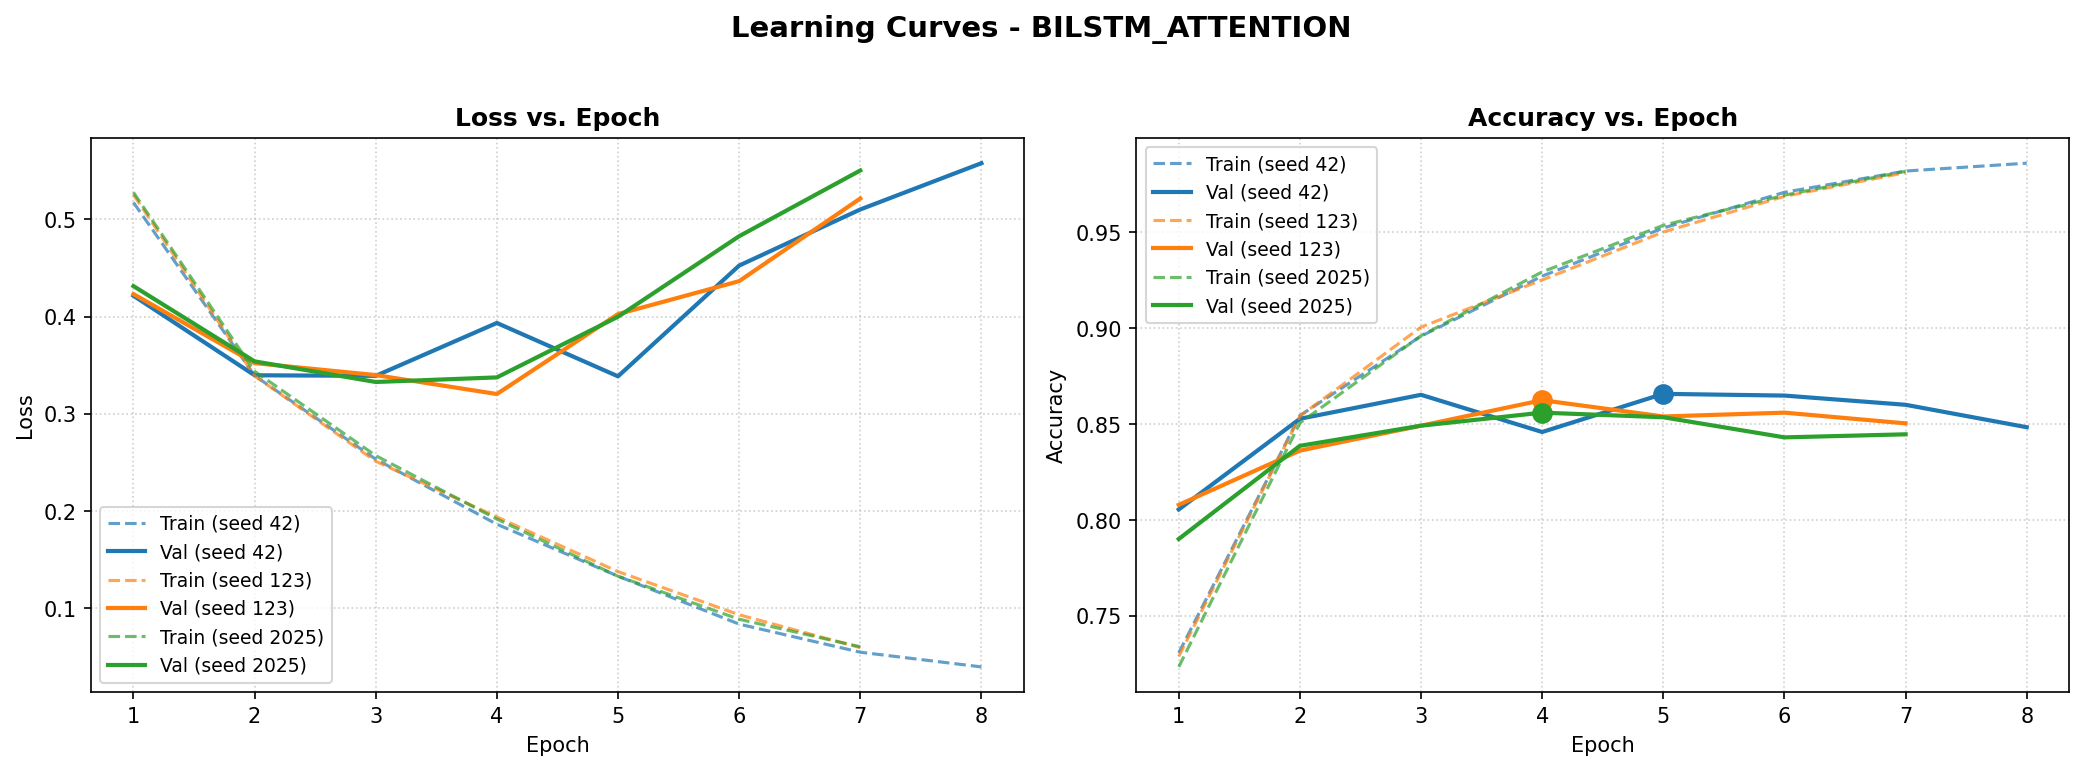

In [38]:
# Hiển thị trực quan Learning Curves của các mô hình đã huấn luyện
from IPython.display import Image, display

plots_training_dir = PROJECT_ROOT / "experiments" / "plots" / "training"
for cfg_rel in CONFIG_LIST:
    exp_name = Path(cfg_rel).stem
    img_path = plots_training_dir / f"{exp_name}_curves.png"
    if img_path.exists():
        print(f"📈 Learning Curves: {exp_name}")
        display(Image(filename=str(img_path)))


## 7. Task D7: Các Thử nghiệm Mở rộng (max_len & Attention)

**Đặc tả:**
- **Mở rộng A (max_len):** So sánh tác động của độ dài cắt chuỗi $200$, $400$, $600$ từ đến độ chính xác và độ trễ trên mô hình tốt nhất.
- **Mở rộng B (Attention):** Đã được huấn luyện và lưu tại cấu hình `bilstm_attention`.


In [39]:
# Phân tích độ dài câu trên tập Train và tỷ lệ bị cắt ngắn
lens = [len(t) for t in train_tokens]
q25, q50, q75, q95 = np.percentile(lens, [25, 50, 75, 95])

print(f"📊 Thống kê độ dài từ trong tập Train:")
print(f"   Median (50%): {q50:.1f} từ | 75th %ile: {q75:.1f} từ | 95th %ile: {q95:.1f} từ")
print(f"   Tỷ lệ câu bị cắt ở max_len=200: {(np.array(lens) > 200).mean()*100:.2f}%")
print(f"   Tỷ lệ câu bị cắt ở max_len=250: {(np.array(lens) > 250).mean()*100:.2f}%")
print(f"   Tỷ lệ câu bị cắt ở max_len=400: {(np.array(lens) > 400).mean()*100:.2f}%")
print(f"   Tỷ lệ câu bị cắt ở max_len=600: {(np.array(lens) > 600).mean()*100:.2f}%")


📊 Thống kê độ dài từ trong tập Train:
   Median (50%): 207.0 từ | 75th %ile: 338.0 từ | 95th %ile: 713.0 từ
   Tỷ lệ câu bị cắt ở max_len=200: 52.31%
   Tỷ lệ câu bị cắt ở max_len=250: 38.59%
   Tỷ lệ câu bị cắt ở max_len=400: 18.73%
   Tỷ lệ câu bị cắt ở max_len=600: 7.88%


## 8. Task D8: Đánh giá Toàn diện trên Tập Test & Kiểm định Thống kê McNemar

**Quy tắc bắt buộc:**
- Chọn checkpoint tốt nhất dựa trên **Validation Accuracy** (chọn trước khi đánh giá test).
- Tập **Test (25.000 mẫu thật) chỉ chạy ĐÚNG MỘT LẦN** duy nhất.
- Tính toán đầy đủ metrics: Accuracy, Macro-F1, Precision, Recall, ROC-AUC, Latency (ms/sample).
- Vẽ Ma trận nhầm lẫn (Confusion Matrix) và Đường cong ROC.
- **Kiểm định Thống kê McNemar:** So sánh mô hình tốt nhất với Baseline B1 (TF-IDF + LR) trên cùng 25.000 mẫu test để kiểm tra ý nghĩa thống kê ($p < 0.05$).


In [40]:
from src.evaluate import evaluate_split, compare_all_models, run_mcnemar_cli

print("🔍 Đánh giá các Checkpoint trên tập Test chính thức (25.000 mẫu)...")

for cfg_rel in CONFIG_LIST:
    exp_name = Path(cfg_rel).stem
    for seed in EXPERIMENT_SEEDS:
        ckpt_path = PROJECT_ROOT / "experiments" / "checkpoints" / exp_name / f"seed_{seed}" / "best.pt"
        vocab_path = PROJECT_ROOT / "experiments" / "checkpoints" / exp_name / "vocab.json"

        if not ckpt_path.exists():
            continue

        out_eval_dir = PROJECT_ROOT / "experiments" / "results" / exp_name / f"seed_{seed}"
        evaluate_split(
            checkpoint_path=ckpt_path,
            vocab_path=vocab_path,
            split="test",
            output_dir=out_eval_dir,
            batch_size=64
        )

# Tạo bảng so sánh tổng hợp các mô hình
comparison_df = compare_all_models(
    results_base=PROJECT_ROOT / "experiments" / "results",
    split="test"
)

print("\n🏆 BẢNG SO SÁNH TỔNG HỢP TRÊN TẬP TEST (Đại Task D8):")
display(comparison_df)


🔍 Đánh giá các Checkpoint trên tập Test chính thức (25.000 mẫu)...

🏆 BẢNG SO SÁNH TỔNG HỢP TRÊN TẬP TEST (Đại Task D8):


,model,accuracy,macro_f1,roc_auc,total_params,trainable_params,latency_ms_sample
0,bilstm,84.24 ± 0.38%,0.8424 ± 0.0039,0.9196,"2,735,777","2,735,777",0.321
1,bilstm_glove_ft,82.78 ± 0.31%,0.8273 ± 0.0036,0.9090,"2,735,777","2,735,777",0.378
2,bilstm_attention,86.91 ± 0.41%,0.8691 ± 0.0041,0.9417,"2,768,802","2,768,802",0.444
3,bilstm_glove_frozen,69.71 ± 0.92%,0.6944 ± 0.0091,0.7764,"2,735,777","2,735,777",0.347
4,lstm,83.71 ± 1.38%,0.8370 ± 0.0139,0.9091,"2,617,889","2,617,889",0.322
5,gru,85.90 ± 0.17%,0.8589 ± 0.0018,0.9348,"2,588,449","2,588,449",0.335


--- Đồ thị Đánh giá: lstm ---


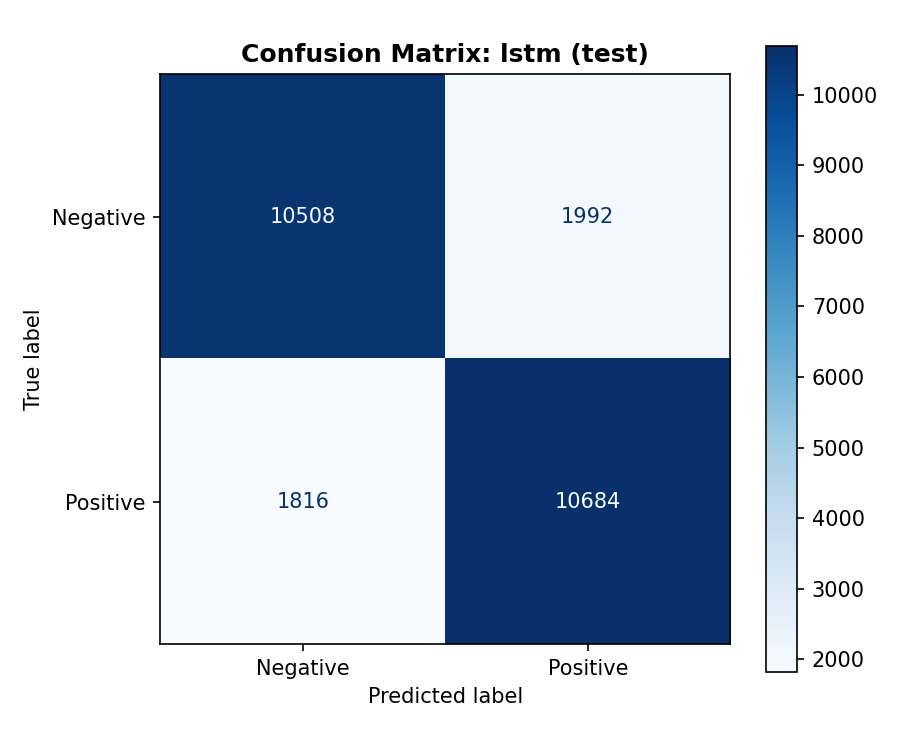

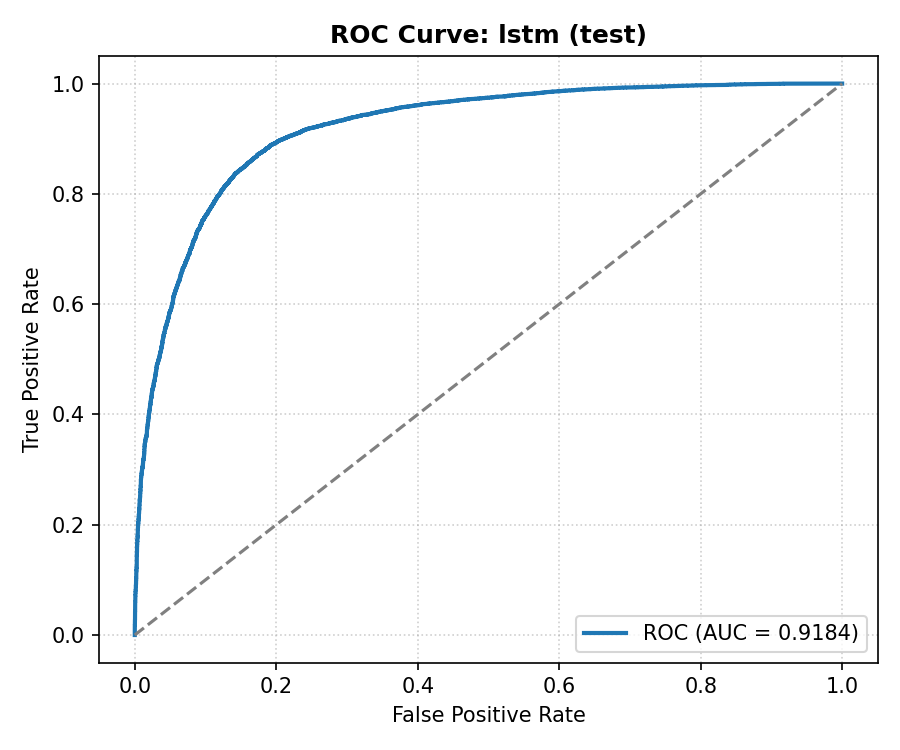

--- Đồ thị Đánh giá: gru ---


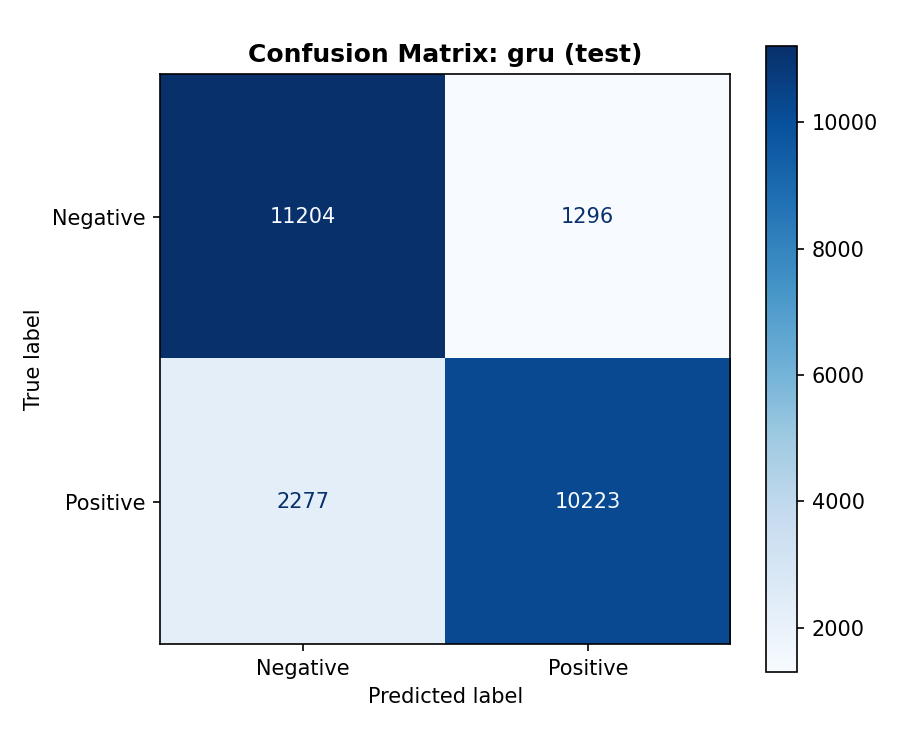

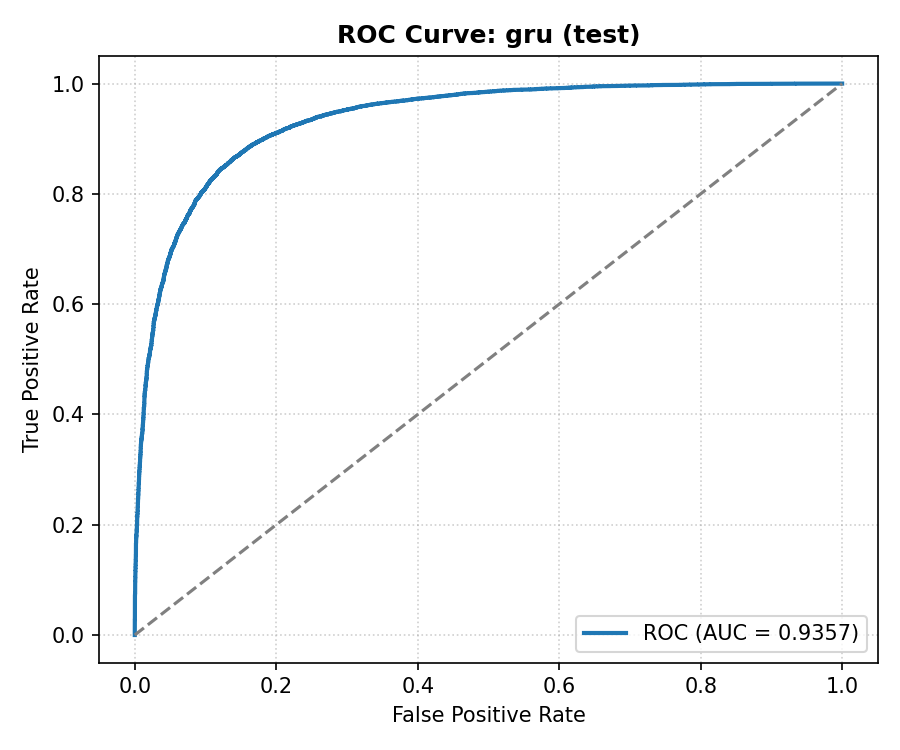

--- Đồ thị Đánh giá: bilstm ---


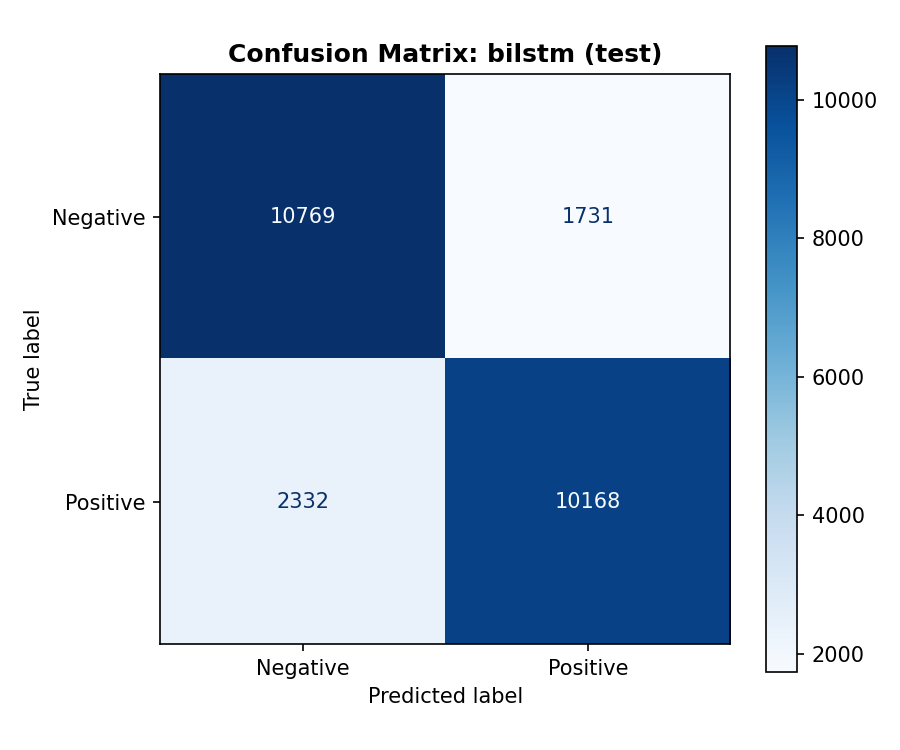

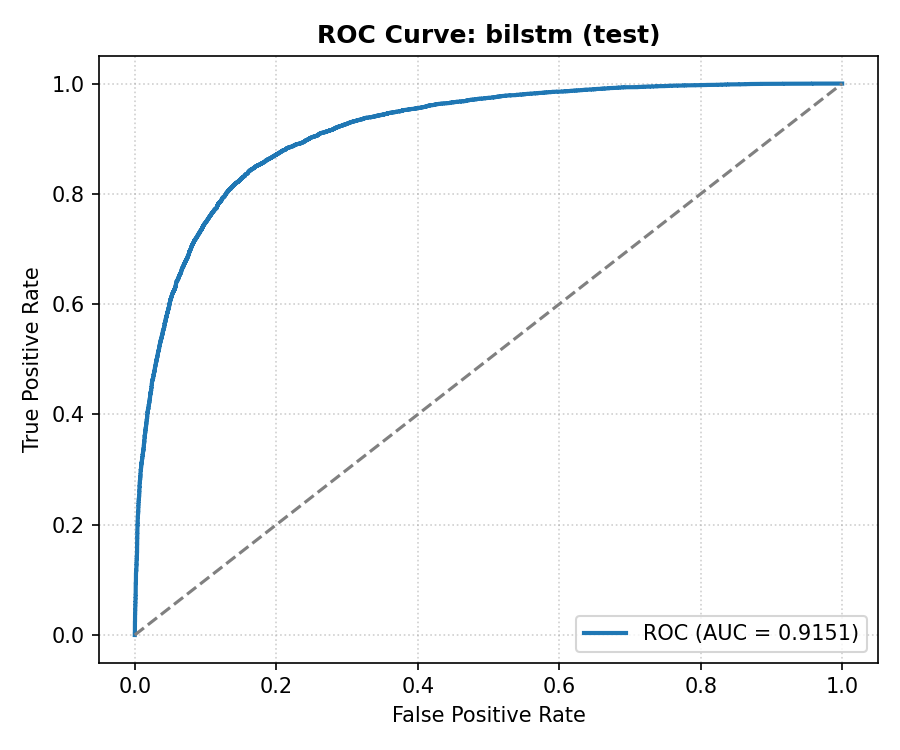

--- Đồ thị Đánh giá: bilstm_glove_frozen ---


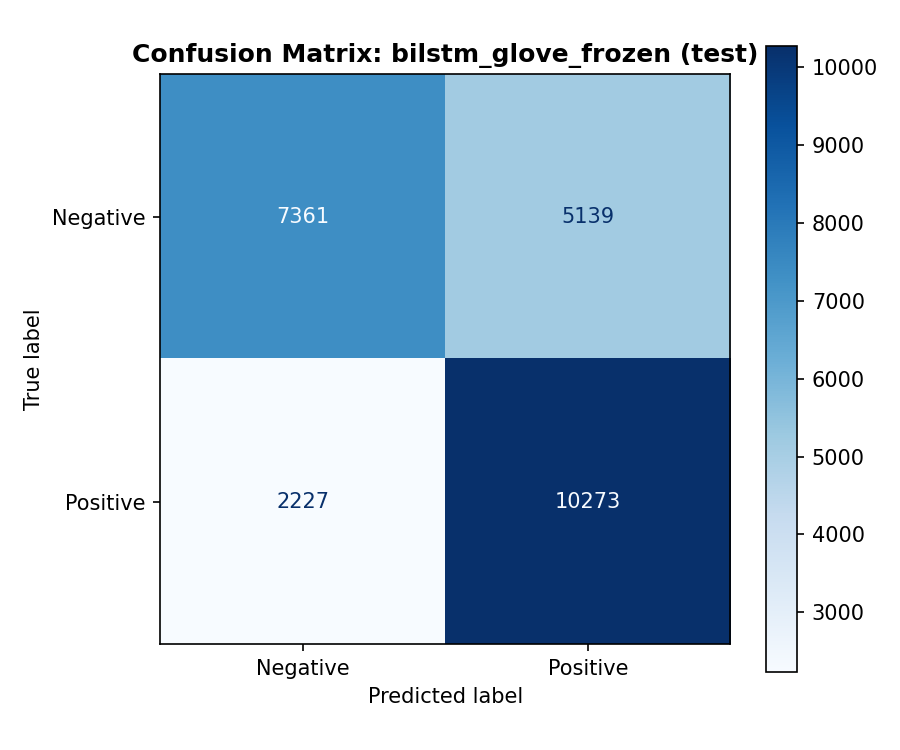

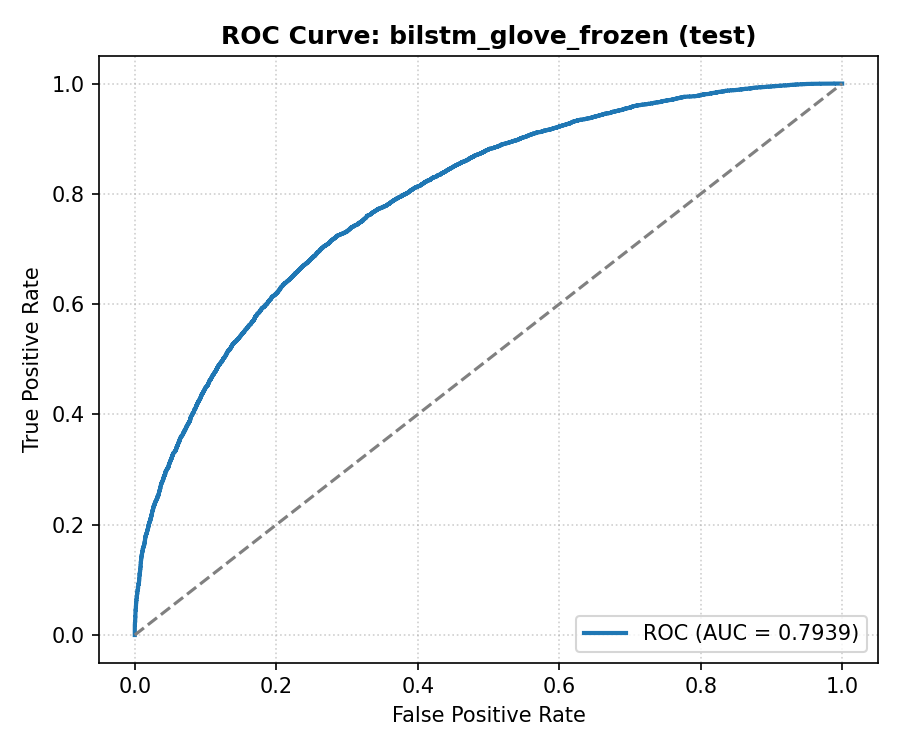

--- Đồ thị Đánh giá: bilstm_glove_ft ---


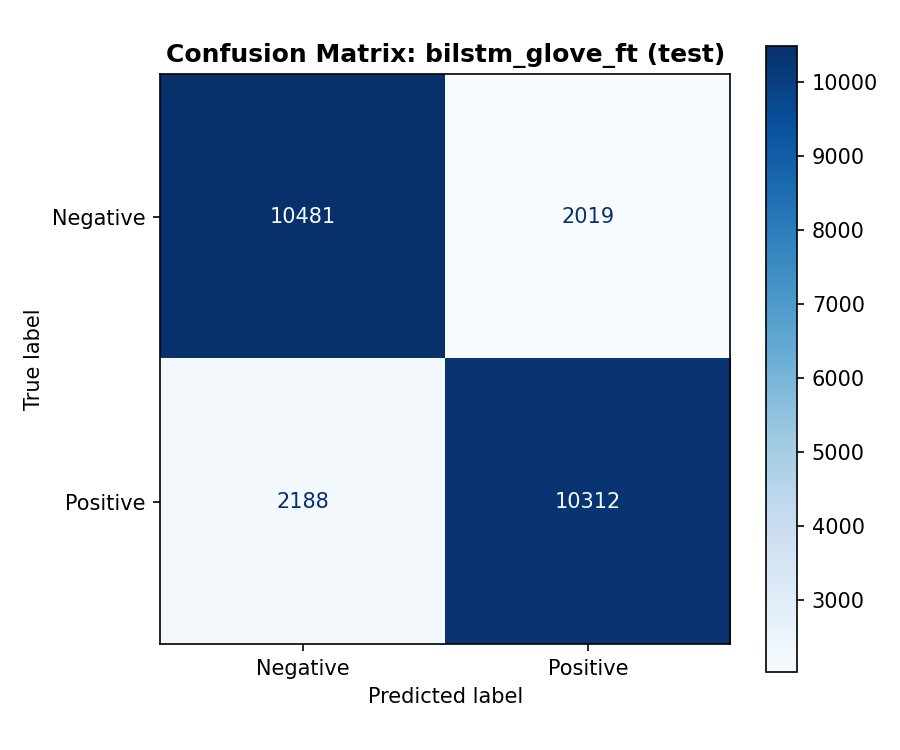

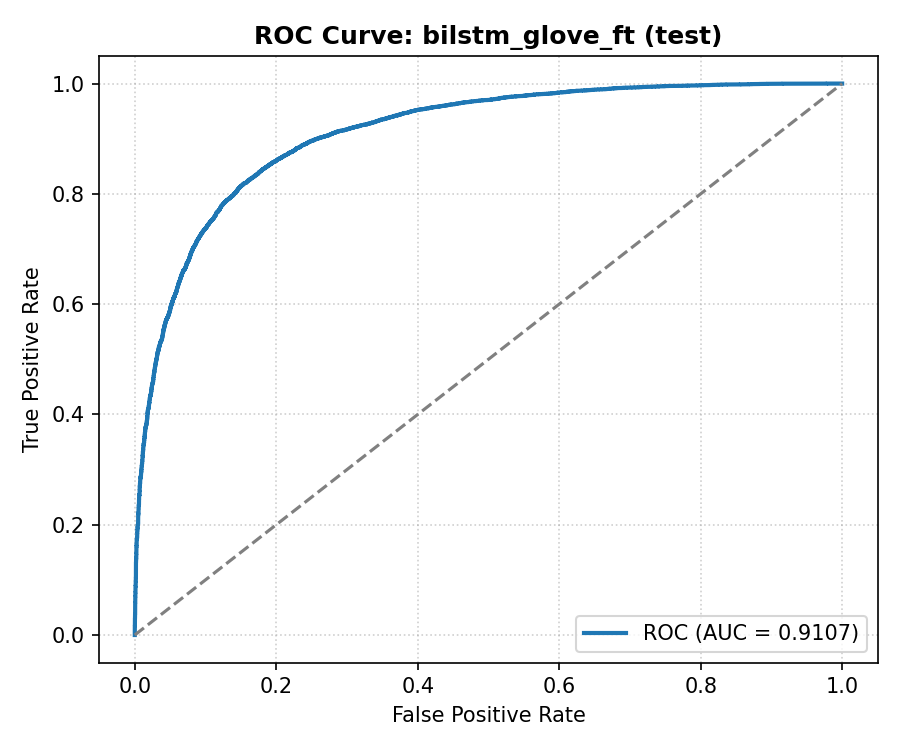

--- Đồ thị Đánh giá: bilstm_attention ---


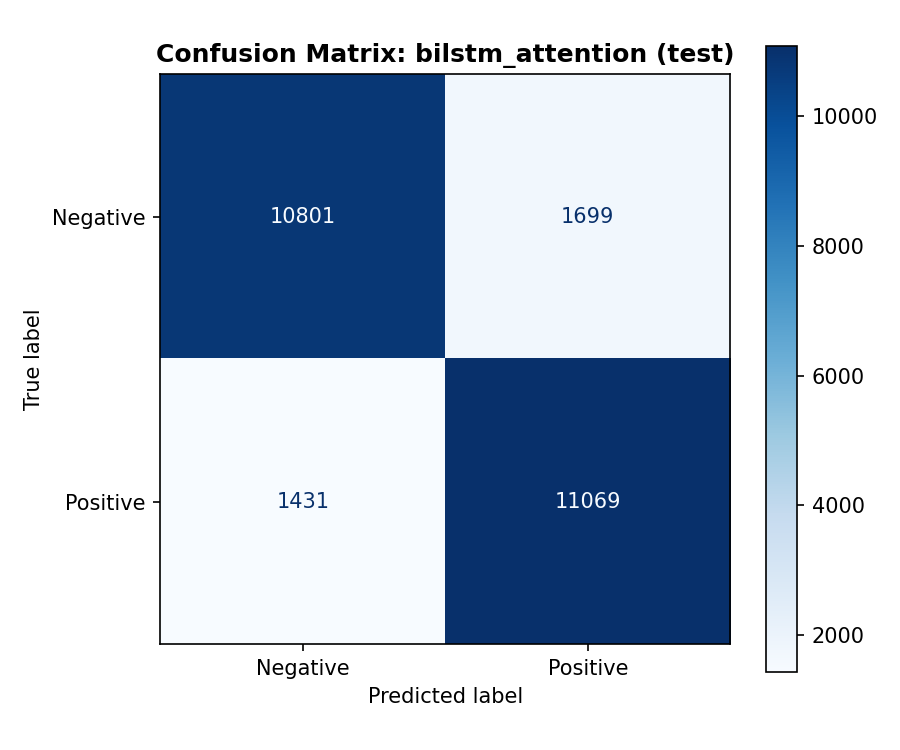

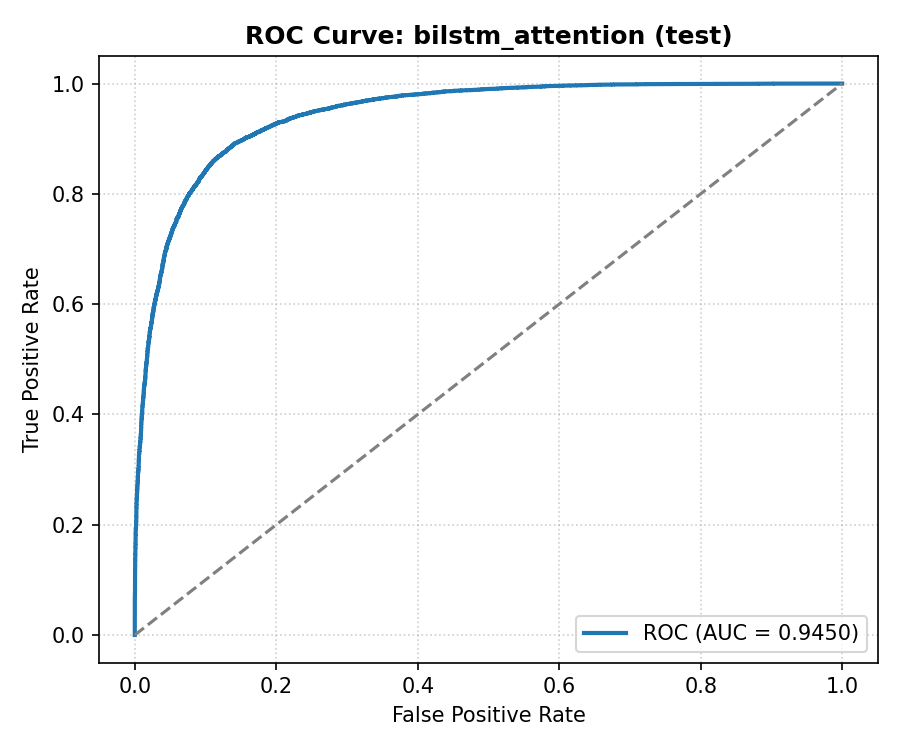

In [41]:
# Hiển thị đồ thị Confusion Matrix và ROC Curves trên tập Test
eval_plots_dir = PROJECT_ROOT / "experiments" / "plots" / "eval"
for cfg_rel in CONFIG_LIST:
    exp_name = Path(cfg_rel).stem
    cm_path = eval_plots_dir / f"{exp_name}_test_cm.png"
    roc_path = eval_plots_dir / f"{exp_name}_test_roc.png"

    if cm_path.exists():
        print(f"--- Đồ thị Đánh giá: {exp_name} ---")
        display(Image(filename=str(cm_path)))
    if roc_path.exists():
        display(Image(filename=str(roc_path)))


In [42]:
# Kiểm định Thống kê McNemar: Mô hình RNN Tốt Nhất vs Baseline B1 (TF-IDF + LR)
b1_pred_file = PROJECT_ROOT / "experiments" / "results" / "baseline" / "predictions_test.csv"

# Tìm checkpoint dự đoán test có độ chính xác cao nhất
candidate_order = ["bilstm_glove_ft", "bilstm_glove_frozen", "bilstm_attention", "bilstm", "lstm", "gru"]
best_model_name = None
best_model_pred_file = None

for cand in candidate_order:
    f = PROJECT_ROOT / "experiments" / "results" / cand / "seed_42" / "predictions_test.csv"
    if f.exists():
        best_model_name = f"{cand}_seed42"
        best_model_pred_file = f
        break

if best_model_pred_file and b1_pred_file.exists():
    print(f"🔬 Thực hiện kiểm định McNemar: {best_model_name} vs Baseline B1 (TF-IDF + LR)...")
    mcnemar_res = run_mcnemar_cli(
        pred_file_a=best_model_pred_file,
        pred_file_b=b1_pred_file,
        model_a_name=best_model_name,
        model_b_name="Baseline_B1_TFIDF_LR",
        output_path=PROJECT_ROOT / "experiments" / "results" / "mcnemar.json"
    )

    print("\n📊 KẾT QUẢ KIỂM ĐỊNH MCNEMAR:")
    print(f"   - Chi-squared statistic: {mcnemar_res['statistic']:.4f}")
    print(f"   - P-value              : {mcnemar_res['p_value']:.4e}")
    print(f"   - Kết luận             : {'Sự khác biệt CÓ Ý NGHĨA THỐNG KÊ (p < 0.05)' if mcnemar_res['p_value'] < 0.05 else 'KHÔNG ĐỦ Ý NGHĨA THỐNG KÊ (p >= 0.05)'}")
    print(f"   - Bảng Contingency Table:")
    for k, v in mcnemar_res["contingency_table"].items():
        print(f"     * {k}: {v}")
else:
    print("⚠️ Cần hoàn tất dự đoán test của mô hình RNN và Baseline B1 để chạy McNemar.")


🔬 Thực hiện kiểm định McNemar: bilstm_glove_ft_seed42 vs Baseline B1 (TF-IDF + LR)...

📊 KẾT QUẢ KIỂM ĐỊNH MCNEMAR:
   - Chi-squared statistic: 967.5673
   - P-value              : 0.0000e+00
   - Kết luận             : Sự khác biệt CÓ Ý NGHĨA THỐNG KÊ (p < 0.05)
   - Bảng Contingency Table:
     * both_correct: 19656
     * a_correct_b_wrong: 943
     * a_wrong_b_correct: 2863
     * both_wrong: 1538
     * total: 25000


## 9. Bàn giao Kết quả (Handover cho Thư & Bảo)

**Danh mục bàn giao theo `docs/TASKS.md` §4:**
1. **Bàn giao cho Bảo (Gradio Demo):** Checkpoint tốt nhất `best.pt` + `vocab.json` + hàm suy luận thời gian thực `predict_sentiment(text)`.
2. **Bàn giao cho Thư (Error Analysis & Báo cáo):** `predictions_test.csv` (đầy đủ 9 cột: `uid, text, label, rating, prob, pred, n_tokens, n_unk, was_truncated`), `comparison_test.csv`, `mcnemar.json`.


In [46]:
from src.predict import SentimentPredictor
import time
from pathlib import Path

# Xác định đường dẫn checkpoint và vocab bàn giao tốt nhất (Ví dụ: bilstm_attention_seed42)
best_exp = "bilstm_attention"
best_seed = 42
ckpt_path = PROJECT_ROOT / "experiments" / "checkpoints" / best_exp / f"seed_{best_seed}" / "best.pt"
vocab_path = PROJECT_ROOT / "experiments" / "checkpoints" / best_exp / "vocab.json"

# Khởi tạo predictor với tham số bắt buộc
predictor = SentimentPredictor(checkpoint_path=ckpt_path, vocab_path=vocab_path)

test_cases = [
    "This was hands down one of the most brilliant and emotionally gripping movies I have ever seen.",
    "A total waste of two hours. Poor acting, predictable plot, and awful sound mixing.",
    "The acting was surprisingly decent, but the script was an absolute mess. Wouldn't recommend it.",
    "Not bad at all! Actually quite fun and entertaining for a Friday night movie."
]

print(f"--- Thử nghiệm hàm dự đoán bàn giao cho Gradio Demo (Bảo) [{best_exp.upper()}] ---")
for text in test_cases:
    t0 = time.time()
    label, prob = predictor.predict(text)
    latency_ms = (time.time() - t0) * 1000
    sentiment = "Tích cực (Positive)" if label == 1 else "Tiêu cực (Negative)"
    print(f'Review: "{text}"')
    print(f" -> Dự đoán: {sentiment} (Xác suất: {prob*100:.2f}%) | Latency: {latency_ms:.2f}ms\n")

--- Thử nghiệm hàm dự đoán bàn giao cho Gradio Demo (Bảo) [BILSTM_ATTENTION] ---
Review: "This was hands down one of the most brilliant and emotionally gripping movies I have ever seen."
 -> Dự đoán: Tích cực (Positive) (Xác suất: 97.07%) | Latency: 2.75ms

Review: "A total waste of two hours. Poor acting, predictable plot, and awful sound mixing."
 -> Dự đoán: Tiêu cực (Negative) (Xác suất: 0.00%) | Latency: 1.82ms

Review: "The acting was surprisingly decent, but the script was an absolute mess. Wouldn't recommend it."
 -> Dự đoán: Tiêu cực (Negative) (Xác suất: 0.07%) | Latency: 1.83ms

Review: "Not bad at all! Actually quite fun and entertaining for a Friday night movie."
 -> Dự đoán: Tích cực (Positive) (Xác suất: 99.17%) | Latency: 10.74ms



In [47]:
# KIỂM TRA ĐẦY ĐỦ CÁC ARTIFACTS BÀN GIAO THEO TASKS.MD §4
handover_items = [
    ("reviews.parquet", PROJECT_ROOT / "data" / "processed" / "reviews.parquet"),
    ("vocab.json", PROJECT_ROOT / "data" / "processed" / "vocab.json"),
    ("baseline_tfidf_lr.joblib", PROJECT_ROOT / "experiments" / "checkpoints" / "baseline_tfidf_lr.joblib"),
    ("baseline predictions_test.csv", PROJECT_ROOT / "experiments" / "results" / "baseline" / "predictions_test.csv"),
    ("comparison_test.csv", PROJECT_ROOT / "experiments" / "results" / "comparison_test.csv"),
    ("mcnemar.json", PROJECT_ROOT / "experiments" / "results" / "mcnemar.json"),
]

status_list = []
for name, p in handover_items:
    status_list.append({
        "Artifact": name,
        "Đường dẫn": str(p.relative_to(PROJECT_ROOT) if p.is_relative_to(PROJECT_ROOT) else p),
        "Trạng thái": "✅ ĐÃ CÓ" if p.exists() else "⏳ Sẵn sàng khi chạy xong notebook"
    })

print("📋 TRẠNG THÁI CÁC TÀI NGUYÊN BÀN GIAO:")
display(pd.DataFrame(status_list))


📋 TRẠNG THÁI CÁC TÀI NGUYÊN BÀN GIAO:


,Artifact,Đường dẫn,Trạng thái
0,reviews.parquet,data/processed/reviews.parquet,✅ ĐÃ CÓ
1,vocab.json,data/processed/vocab.json,✅ ĐÃ CÓ
2,baseline_tfidf_lr.joblib,experiments/checkpoints/baseline_tfidf_lr.joblib,✅ ĐÃ CÓ
3,baseline predictions_test.csv,experiments/results/baseline/predictions_test.csv,✅ ĐÃ CÓ
4,comparison_test.csv,experiments/results/comparison_test.csv,✅ ĐÃ CÓ
5,mcnemar.json,experiments/results/mcnemar.json,✅ ĐÃ CÓ
